# PHẦN 3 — FEATURE ENGINEERING & TEMPORAL TRAIN/TEST SPLIT

**Đề tài:** COVID-19 tại 3 châu lục (Bắc Mỹ, Châu Á, Châu Phi) — Time Series EDA + Feature Engineering + Machine Learning
**Người thực hiện:** Hiệp (Thành viên 3)
**Nhận dữ liệu từ:** Thành viên 1 (Phát) — `data/covid19_continent_daily_totals_prepared.csv`
**Bàn giao cho:** Thành viên 4 và 5 (huấn luyện mô hình), Thành viên 6 (đánh giá, tổng hợp)

**Mục tiêu dự báo:** `New_Confirmed` — số ca mắc mới theo ngày.

**Notebook này làm 2 việc:**
1. Tạo đặc trưng (feature) cho bài toán dự báo, chỉ dùng thông tin của quá khứ và kiểm tra không rò rỉ dữ liệu tương lai.
2. Chia Train/Test theo thời gian (80% đầu / 20% cuối, không shuffle) và xuất file chung để cả nhóm dùng cùng một dữ liệu.

In [4]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

print("Pandas:", pd.__version__)
print("Thư mục hiện tại:", Path.cwd())

Pandas: 2.2.3
Thư mục hiện tại: /content


## 1. Đọc dữ liệu đầu vào

Dùng file `covid19_continent_daily_totals_prepared.csv` do Thành viên 1 bàn giao. File này đã gộp 3 file CSV gốc theo ngày và theo châu lục (mỗi châu lục 188 ngày).

In [6]:
# Notebook nằm trong thư mục notebooks/, dữ liệu nằm trong data/
DATA_DIR = Path.cwd().parent / "data"
if not DATA_DIR.exists():              # phòng khi chạy từ thư mục gốc của repo
    DATA_DIR = Path.cwd() / "data"

INPUT_FILE = DATA_DIR / "covid19_continent_daily_totals_prepared.csv"

raw = pd.read_csv(INPUT_FILE, parse_dates=["Date"])
raw = raw.sort_values(["Continent", "Date"]).reset_index(drop=True)

print("File:", INPUT_FILE.name)
print("Số dòng, số cột:", raw.shape)
display(raw.head())

File: covid19_continent_daily_totals_prepared.csv
Số dòng, số cột: (564, 12)


,Date,Confirmed,Deaths,Recovered,Active,Continent,New_Confirmed,New_Deaths,New_Recovered,Rolling_7D_New_Confirmed,Rolling_14D_New_Confirmed,Cumulative_Confirmed_Total
0,2020-01-22,0,0,0,0,Africa,0.0,0.0,0.0,0.0,0.0,0
1,2020-01-23,0,0,0,0,Africa,0.0,0.0,0.0,0.0,0.0,0
2,2020-01-24,0,0,0,0,Africa,0.0,0.0,0.0,0.0,0.0,0
3,2020-01-25,0,0,0,0,Africa,0.0,0.0,0.0,0.0,0.0,0
4,2020-01-26,0,0,0,0,Africa,0.0,0.0,0.0,0.0,0.0,0


### 1.1. Kiểm tra nhanh dữ liệu đầu vào
Kiểm tra lại các điều kiện mà phần feature engineering phụ thuộc vào: ngày liên tục, không thiếu, không trùng và `New_Confirmed` đúng bằng sai phân của `Confirmed`.

In [7]:
continents = ["North America", "Asia", "Africa"]   # thứ tự thống nhất cho toàn nhóm

rows = []
for c in continents:
    g = raw[raw["Continent"] == c].sort_values("Date")
    full_range = pd.date_range(g["Date"].min(), g["Date"].max(), freq="D")

    # New_Confirmed trong file phải bằng Confirmed.diff() (bỏ ngày đầu vì không có ngày trước)
    diff_check = g["Confirmed"].diff().iloc[1:]
    nc_check = g["New_Confirmed"].iloc[1:]

    rows.append({
        "Châu lục": c,
        "Số dòng": len(g),
        "Ngày đầu": g["Date"].min().date(),
        "Ngày cuối": g["Date"].max().date(),
        "Thiếu ngày": len(full_range.difference(g["Date"])),
        "Ngày trùng": int(g["Date"].duplicated().sum()),
        "Giá trị NaN": int(g.isna().sum().sum()),
        "New_Confirmed < 0": int((g["New_Confirmed"] < 0).sum()),
        "New_Confirmed lệch diff()": int((~np.isclose(diff_check, nc_check)).sum()),
    })

input_check = pd.DataFrame(rows)
display(input_check)

assert (input_check["Thiếu ngày"] == 0).all()
assert (input_check["Ngày trùng"] == 0).all()
assert (input_check["Giá trị NaN"] == 0).all()
assert (input_check["New_Confirmed < 0"] == 0).all()
assert (input_check["New_Confirmed lệch diff()"] == 0).all()
print("Dữ liệu đầu vào hợp lệ.")

,Châu lục,Số dòng,Ngày đầu,Ngày cuối,Thiếu ngày,Ngày trùng,Giá trị NaN,New_Confirmed < 0,New_Confirmed lệch diff()
0,North America,188,2020-01-22,2020-07-27,0,0,0,0,0
1,Asia,188,2020-01-22,2020-07-27,0,0,0,0,0
2,Africa,188,2020-01-22,2020-07-27,0,0,0,0,0


Dữ liệu đầu vào hợp lệ.


## 2. Quy tắc tạo đặc trưng

Gọi $y_t$ là `New_Confirmed` của ngày $t$. Mọi đặc trưng của ngày $t$ **chỉ được dùng thông tin đến hết ngày $t-1$**.

| Cột | Công thức | Vai trò |
|---|---|---|
| `New_Confirmed` | $y_t$ | **Target Level** (dùng cho Linear Regression baseline) |
| `Diff_1` | $y_t - y_{t-1}$ | **Target Diff** (dùng cho Ridge, Random Forest, Gradient Boosting, Decision Tree). Đây là target, **không phải feature** |
| `Lag_1`, `Lag_2`, `Lag_3`, `Lag_7` | $y_{t-1}, y_{t-2}, y_{t-3}, y_{t-7}$ | Feature |
| `Roll_Mean_7` | trung bình của $y_{t-7}, \dots, y_{t-1}$ (dùng `shift(1)`) | Feature |
| `Roll_Std_7` | độ lệch chuẩn của $y_{t-7}, \dots, y_{t-1}$ (dùng `shift(1)`) | Feature |
| `DayOfWeek` | 0 = Thứ Hai … 6 = Chủ Nhật | Feature |
| `IsWeekend` | 1 nếu Thứ Bảy/Chủ Nhật | Feature |
| `Month` | tháng của ngày $t$ | Có trong dữ liệu, xem mục 7 về việc có nên dùng không |

**Quy ước dự báo cho mô hình Diff:** $\hat{y}_t = \text{Lag\_1}_t + \widehat{\text{Diff\_1}}_t$

**Xử lý ngày đầu tiên (22/01/2020):** cột `New_Confirmed` của ngày này được điền `0` vì không có ngày trước để lấy sai phân. Với Châu Á, số ca tích lũy ngày đó đã là 554 nên giá trị `0` là sai thực tế. Vì vậy **bỏ ngày đầu tiên của cả 3 châu lục** trước khi tạo feature.

**Không dùng** các cột `Rolling_7D_New_Confirmed` và `Rolling_14D_New_Confirmed` có sẵn trong file: chúng tính cả ngày hiện tại (không `shift(1)`) nên sẽ làm lộ target.

In [8]:
LAGS = [1, 2, 3, 7]
ROLL_WINDOW = 7

def build_features(g):
    """Tạo feature cho MỘT châu lục. g phải có cột Date, Continent, New_Confirmed."""
    g = g.sort_values("Date").reset_index(drop=True)

    # Bỏ ngày đầu tiên: New_Confirmed = 0 là giá trị điền, không phải số thật
    g = g.iloc[1:].reset_index(drop=True)

    y = g["New_Confirmed"]
    out = pd.DataFrame({
        "Date": g["Date"],
        "Continent": g["Continent"],
        "New_Confirmed": y,           # target Level
        "Diff_1": y.diff(),           # target Diff
    })

    # Lag: giá trị của các ngày trước
    for k in LAGS:
        out[f"Lag_{k}"] = y.shift(k)

    # Rolling: shift(1) trước khi rolling để cửa sổ chỉ gồm t-7 ... t-1
    past = y.shift(1)
    out["Roll_Mean_7"] = past.rolling(window=ROLL_WINDOW).mean()
    out["Roll_Std_7"] = past.rolling(window=ROLL_WINDOW).std()

    # Biến lịch (chỉ phụ thuộc vào chính ngày t nên không rò rỉ)
    out["DayOfWeek"] = out["Date"].dt.dayofweek
    out["IsWeekend"] = (out["DayOfWeek"] >= 5).astype(int)
    out["Month"] = out["Date"].dt.month
    return out

TARGET_LEVEL = "New_Confirmed"
TARGET_DIFF = "Diff_1"
FEATURES_ALL = ["Lag_1", "Lag_2", "Lag_3", "Lag_7",
                "Roll_Mean_7", "Roll_Std_7",
                "DayOfWeek", "IsWeekend", "Month"]

feat_raw = pd.concat(
    [build_features(raw[raw["Continent"] == c]) for c in continents],
    ignore_index=True,
)

print("Trước khi bỏ NaN:", feat_raw.shape)
display(feat_raw[feat_raw["Continent"] == "Asia"].head(10))

Trước khi bỏ NaN: (561, 13)


,Date,Continent,New_Confirmed,Diff_1,Lag_1,Lag_2,Lag_3,Lag_7,Roll_Mean_7,Roll_Std_7,DayOfWeek,IsWeekend,Month
187,2020-01-23,Asia,99.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,0,1
188,2020-01-24,Asia,284.0,185.0,99.0,NaN,NaN,NaN,NaN,NaN,4,0,1
189,2020-01-25,Asia,492.0,208.0,284.0,99.0,NaN,NaN,NaN,NaN,5,1,1
190,2020-01-26,Asia,676.0,184.0,492.0,284.0,99.0,NaN,NaN,NaN,6,1,1
191,2020-01-27,Asia,807.0,131.0,676.0,492.0,284.0,NaN,NaN,NaN,0,0,1
192,2020-01-28,Asia,2646.0,1839.0,807.0,676.0,492.0,NaN,NaN,NaN,1,0,1
193,2020-01-29,Asia,585.0,-2061.0,2646.0,807.0,676.0,NaN,NaN,NaN,2,0,1
194,2020-01-30,Asia,2065.0,1480.0,585.0,2646.0,807.0,99.0,798.428571,848.711741,3,0,1
195,2020-01-31,Asia,1683.0,-382.0,2065.0,585.0,2646.0,284.0,1079.285714,902.284825,4,0,1
196,2020-02-01,Asia,2102.0,419.0,1683.0,2065.0,585.0,492.0,1279.142857,850.205745,5,1,2


### 2.1. Loại bỏ dòng NaN do lag/rolling
Lag 7 và rolling 7 ngày làm các ngày đầu của chuỗi chưa đủ dữ liệu quá khứ nên bị NaN. Các dòng này bị loại ra khỏi tập dữ liệu.

In [9]:
needed_cols = [TARGET_LEVEL, TARGET_DIFF] + FEATURES_ALL

rows = []
for c in continents:
    g = feat_raw[feat_raw["Continent"] == c]
    rows.append({
        "Châu lục": c,
        "Dòng sau khi bỏ ngày đầu": len(g),
        "Dòng NaN bị loại": int(g[needed_cols].isna().any(axis=1).sum()),
        "Dòng còn lại": int(g[needed_cols].notna().all(axis=1).sum()),
    })
display(pd.DataFrame(rows))

feat = (
    feat_raw.dropna(subset=needed_cols)
    .sort_values(["Continent", "Date"])
    .reset_index(drop=True)
)
print("Kích thước dữ liệu feature cuối cùng:", feat.shape)
print("Còn NaN:", int(feat[needed_cols].isna().sum().sum()))
print("Còn vô cực:", int(np.isinf(feat[needed_cols].to_numpy(dtype=float)).sum()))

,Châu lục,Dòng sau khi bỏ ngày đầu,Dòng NaN bị loại,Dòng còn lại
0,North America,187,7,180
1,Asia,187,7,180
2,Africa,187,7,180


Kích thước dữ liệu feature cuối cùng: (540, 13)
Còn NaN: 0
Còn vô cực: 0


## 3. Kiểm tra không rò rỉ dữ liệu tương lai

Dùng 4 kiểm tra độc lập:

1. **Lag:** `Lag_k` của ngày $t$ phải đúng bằng $y_{t-k}$.
2. **Rolling:** `Roll_Mean_7` và `Roll_Std_7` được tính lại bằng NumPy từ đúng 7 ngày trước ngày $t$, rồi so với cột đã tạo.
3. **Kiểm tra nhiễu tương lai (perturbation):** thay toàn bộ $y$ từ ngày $t_0$ trở đi bằng số ngẫu nhiên rồi tạo lại feature. Nếu feature của các ngày $\le t_0$ **không đổi** thì feature không dùng dữ liệu từ ngày $t_0$ trở đi. Đây là kiểm tra mạnh nhất.
4. **Khôi phục Diff:** `Lag_1 + Diff_1` phải đúng bằng `New_Confirmed` (để chuyển dự báo Diff về mức ca mới).

In [10]:
rng = np.random.default_rng(RANDOM_STATE)
leak_rows = []

for c in continents:
    g_src = raw[raw["Continent"] == c].sort_values("Date")
    g = feat[feat["Continent"] == c].reset_index(drop=True)

    # Dãy y gốc (đã bỏ ngày đầu) và vị trí của từng dòng feature trong dãy đó
    y_full = g_src.iloc[1:].set_index("Date")["New_Confirmed"]
    pos = y_full.index.get_indexer(g["Date"])

    # (1) Lag đúng bằng giá trị quá khứ
    lag_ok = all(
        np.allclose(g[f"Lag_{k}"].to_numpy(), y_full.to_numpy()[pos - k])
        for k in LAGS
    )

    # (2) Rolling tính lại bằng NumPy từ đúng 7 ngày trước đó
    ref_mean = np.array([y_full.to_numpy()[p - 7:p].mean() for p in pos])
    ref_std = np.array([y_full.to_numpy()[p - 7:p].std(ddof=1) for p in pos])
    roll_ok = np.allclose(g["Roll_Mean_7"], ref_mean) and np.allclose(g["Roll_Std_7"], ref_std)

    # (3) Kiểm tra nhiễu tương lai: phá hết dữ liệu từ ngày t0 trở đi
    t0 = len(g_src.iloc[1:]) // 2
    perturbed = g_src.copy()
    mask = perturbed["Date"] >= y_full.index[t0]
    perturbed.loc[mask, "New_Confirmed"] = rng.integers(10**6, 10**7, mask.sum())
    g_p = build_features(perturbed).dropna(subset=needed_cols).reset_index(drop=True)

    before = g[g["Date"] <= y_full.index[t0]]
    before_p = g_p[g_p["Date"] <= y_full.index[t0]]
    perturb_ok = np.allclose(before[FEATURES_ALL].to_numpy(dtype=float),
                             before_p[FEATURES_ALL].to_numpy(dtype=float))

    # (4) Khôi phục target Level từ Lag_1 + Diff_1
    recon_ok = np.allclose(g["Lag_1"] + g["Diff_1"], g["New_Confirmed"])

    leak_rows.append({"Châu lục": c, "Lag đúng": lag_ok, "Rolling đúng": roll_ok,
                      "Không đổi khi phá tương lai": perturb_ok,
                      "Lag_1 + Diff_1 = New_Confirmed": recon_ok})

leak_report = pd.DataFrame(leak_rows)
display(leak_report)

assert leak_report.drop(columns="Châu lục").all().all(), "Có kiểm tra rò rỉ không đạt!"
assert not any(col in FEATURES_ALL for col in ["New_Confirmed", "Diff_1",
        "Rolling_7D_New_Confirmed", "Rolling_14D_New_Confirmed"])
print("Đạt cả 4 kiểm tra: không phát hiện rò rỉ dữ liệu tương lai.")

,Châu lục,Lag đúng,Rolling đúng,Không đổi khi phá tương lai,Lag_1 + Diff_1 = New_Confirmed
0,North America,True,True,True,True
1,Asia,True,True,True,True
2,Africa,True,True,True,True


Đạt cả 4 kiểm tra: không phát hiện rò rỉ dữ liệu tương lai.


## 4. Chia Train/Test theo thời gian

**Quy tắc chung của nhóm:**
- Chia **riêng từng châu lục**, theo thứ tự thời gian.
- **80% đầu → Train, 20% cuối → Test**, cắt tại `int(n × 0.8)`.
- **Không shuffle.** Mọi mô hình (Thành viên 4, 5) dùng đúng các tập này.

In [11]:
TRAIN_RATIO = 0.8

train_parts, test_parts = [], []
for c in continents:
    g = feat[feat["Continent"] == c].sort_values("Date").reset_index(drop=True)
    split_idx = int(len(g) * TRAIN_RATIO)
    train_parts.append(g.iloc[:split_idx])
    test_parts.append(g.iloc[split_idx:])

train = pd.concat(train_parts, ignore_index=True)
test = pd.concat(test_parts, ignore_index=True)

rows = []
for c in continents:
    tr = train[train["Continent"] == c]
    te = test[test["Continent"] == c]
    rows.append({
        "Châu lục": c,
        "Train: số dòng": len(tr),
        "Train: từ ngày": tr["Date"].min().date(),
        "Train: đến ngày": tr["Date"].max().date(),
        "Test: số dòng": len(te),
        "Test: từ ngày": te["Date"].min().date(),
        "Test: đến ngày": te["Date"].max().date(),
        "Tỷ lệ Train": round(len(tr) / (len(tr) + len(te)), 3),
    })
split_table = pd.DataFrame(rows)
display(split_table)

# Kiểm tra: Train hoàn toàn trước Test, không trùng ngày, không lẫn châu lục
for c in continents:
    tr = train[train["Continent"] == c]
    te = test[test["Continent"] == c]
    assert tr["Date"].max() < te["Date"].min(), f"Train/Test chồng thời gian ở {c}"
    assert tr["Date"].is_monotonic_increasing and te["Date"].is_monotonic_increasing
assert len(train) + len(test) == len(feat)
print("Đạt: Train luôn nằm trước Test về thời gian, không shuffle, không trùng ngày.")

,Châu lục,Train: số dòng,Train: từ ngày,Train: đến ngày,Test: số dòng,Test: từ ngày,Test: đến ngày,Tỷ lệ Train
0,North America,144,2020-01-30,2020-06-21,36,2020-06-22,2020-07-27,0.8
1,Asia,144,2020-01-30,2020-06-21,36,2020-06-22,2020-07-27,0.8
2,Africa,144,2020-01-30,2020-06-21,36,2020-06-22,2020-07-27,0.8


Đạt: Train luôn nằm trước Test về thời gian, không shuffle, không trùng ngày.


### 4.1. Biểu đồ minh họa cách chia Train/Test

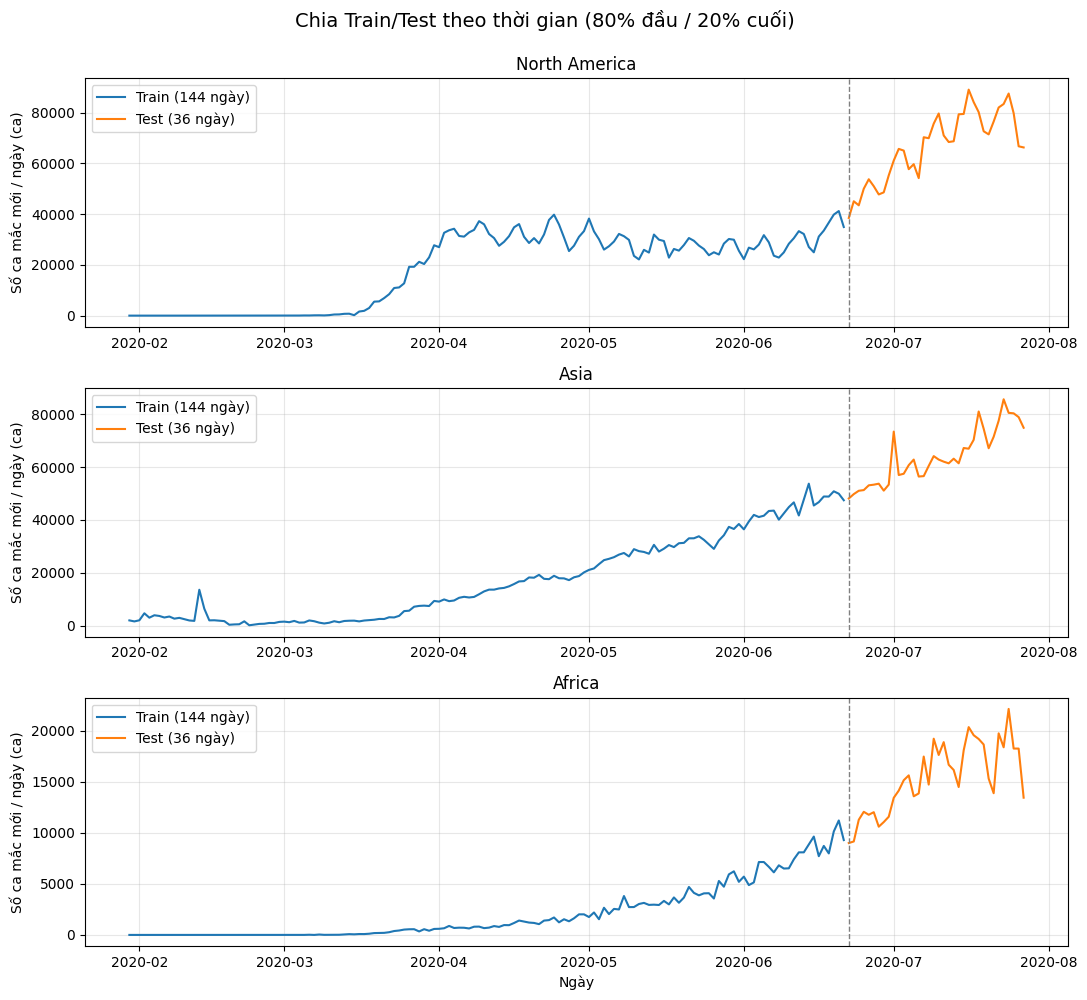

In [12]:
colors = {"Train": "#1f77b4", "Test": "#ff7f0e"}
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=False)

for ax, c in zip(axes, continents):
    tr = train[train["Continent"] == c]
    te = test[test["Continent"] == c]
    ax.plot(tr["Date"], tr["New_Confirmed"], color=colors["Train"], label=f"Train ({len(tr)} ngày)")
    ax.plot(te["Date"], te["New_Confirmed"], color=colors["Test"], label=f"Test ({len(te)} ngày)")
    ax.axvline(te["Date"].min(), color="gray", linestyle="--", linewidth=1)
    ax.set_title(c)
    ax.set_ylabel("Số ca mắc mới / ngày (ca)")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Ngày")
fig.suptitle("Chia Train/Test theo thời gian (80% đầu / 20% cuối)", fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

**Nhận xét biểu đồ:** đường nét đứt là ranh giới Train/Test. Ở cả 3 châu lục, giai đoạn Test nằm trong đợt tăng mạnh cuối kỳ nên mức ca mắc mới trong Test cao hơn hẳn Train. Điều này được định lượng ở mục tiếp theo.

## 5. Mức ca mới giữa Train và Test (phân phối không đồng nhất)

In [13]:
rows = []
for c in continents:
    tr = train[train["Continent"] == c]["New_Confirmed"]
    te = test[test["Continent"] == c]["New_Confirmed"]
    rows.append({
        "Châu lục": c,
        "Trung bình Train": round(tr.mean()),
        "Trung bình Test": round(te.mean()),
        "Test / Train (lần)": round(te.mean() / tr.mean(), 1),
        "Max Train": int(tr.max()),
        "Max Test": int(te.max()),
        "Test có vượt Max Train": bool(te.max() > tr.max()),
    })
shift_table = pd.DataFrame(rows)
display(shift_table)

,Châu lục,Trung bình Train,Trung bình Test,Test / Train (lần),Max Train,Max Test,Test có vượt Max Train
0,North America,18480,66601,3.6,41187,89010,True
1,Asia,17237,63891,3.7,53709,85583,True
2,Africa,2128,15393,7.2,11198,22111,True


**Ý nghĩa với việc xây mô hình (Thành viên 4, 5 cần biết):**
- Trung bình ca mới trong Test cao gấp nhiều lần Train, và Test có ngày vượt cả đỉnh của Train.
- Mô hình cây (Random Forest, Gradient Boosting, Decision Tree) không thể dự báo ra giá trị lớn hơn những gì đã thấy trong Train. Nếu dự báo trực tiếp mức ca mới thì sai số sẽ rất lớn.
- Đây là lý do đề bài yêu cầu các mô hình này dự báo **sai phân (Diff)** rồi cộng lại với `Lag_1`: sai phân ít bị lệch quy mô hơn so với mức ca mới.

## 6. Tương quan giữa feature và target (chỉ tính trên tập Train)

Chỉ dùng Train để không "nhìn trộm" Test.

In [14]:
corr_rows = []
for c in continents:
    tr = train[train["Continent"] == c]
    row = {"Châu lục": c}
    for f in FEATURES_ALL:
        row[f] = round(tr[f].corr(tr[TARGET_LEVEL]), 3)
    corr_rows.append(row)
corr_level = pd.DataFrame(corr_rows).set_index("Châu lục")
print("Tương quan với target Level (New_Confirmed):")
display(corr_level)

corr_rows = []
for c in continents:
    tr = train[train["Continent"] == c]
    row = {"Châu lục": c}
    for f in FEATURES_ALL:
        row[f] = round(tr[f].corr(tr[TARGET_DIFF]), 3)
    corr_rows.append(row)
corr_diff = pd.DataFrame(corr_rows).set_index("Châu lục")
print("Tương quan với target Diff (Diff_1):")
display(corr_diff)

Tương quan với target Level (New_Confirmed):


,Lag_1,Lag_2,Lag_3,Lag_7,Roll_Mean_7,Roll_Std_7,DayOfWeek,IsWeekend,Month
Châu lục,,,,,,,,,
North America,0.984,0.963,0.944,0.950,0.969,0.876,0.057,0.002,0.814
Asia,0.992,0.988,0.989,0.983,0.992,0.481,0.044,0.031,0.934
Africa,0.982,0.979,0.977,0.984,0.989,0.903,0.047,0.031,0.859


Tương quan với target Diff (Diff_1):


,Lag_1,Lag_2,Lag_3,Lag_7,Roll_Mean_7,Roll_Std_7,DayOfWeek,IsWeekend,Month
Châu lục,,,,,,,,,
North America,-0.096,-0.126,-0.114,-0.010,-0.049,0.026,-0.295,-0.480,-0.022
Asia,0.010,0.044,0.077,0.066,0.054,-0.202,0.118,0.036,0.083
Africa,0.022,0.094,0.104,0.118,0.102,-0.068,-0.085,-0.178,0.118


**Nhận xét:** với target Level, các feature Lag và Roll_Mean_7 có tương quan rất cao vì số ca hôm nay gần với những ngày liền trước. Với target Diff, tương quan với các feature thấp hơn nhiều, đúng với bản chất sai phân là phần dao động quanh mức hiện tại, nên bài toán Diff khó hơn nhưng không bị lệch quy mô. Riêng Bắc Mỹ, `IsWeekend` có tương quan âm đáng chú ý với `Diff_1`, gợi ý số ca báo cáo cuối tuần thường giảm so với ngày liền trước.

## 7. Chọn danh sách feature khuyến nghị: có dùng `Month` không?

In [15]:
for c in continents:
    tr_m = [int(m) for m in sorted(train[train["Continent"] == c]["Month"].unique())]
    te_m = [int(m) for m in sorted(test[test["Continent"] == c]["Month"].unique())]
    unseen = sorted(set(te_m) - set(tr_m))
    print(f"{c:14s} | Tháng trong Train: {tr_m} | Tháng trong Test: {te_m} | Tháng chưa từng xuất hiện trong Train: {unseen}")

North America  | Tháng trong Train: [1, 2, 3, 4, 5, 6] | Tháng trong Test: [6, 7] | Tháng chưa từng xuất hiện trong Train: [7]
Asia           | Tháng trong Train: [1, 2, 3, 4, 5, 6] | Tháng trong Test: [6, 7] | Tháng chưa từng xuất hiện trong Train: [7]
Africa         | Tháng trong Train: [1, 2, 3, 4, 5, 6] | Tháng trong Test: [6, 7] | Tháng chưa từng xuất hiện trong Train: [7]


Tập Test có tháng mà Train chưa từng thấy. Với mô hình cây, giá trị `Month` mới này không mang thông tin học được; với mô hình tuyến tính, nó bị ngoại suy theo hệ số. Vì vậy **danh sách feature khuyến nghị cho cả nhóm không gồm `Month`**. Cột `Month` vẫn được giữ trong file xuất ra, ai cần thì có thể thêm vào và nêu rõ trong báo cáo.

In [16]:
FEATURES = ["Lag_1", "Lag_2", "Lag_3", "Lag_7",
            "Roll_Mean_7", "Roll_Std_7",
            "DayOfWeek", "IsWeekend"]

print("Danh sách feature khuyến nghị (dùng chung cho cả 5 mô hình):")
for i, f in enumerate(FEATURES, 1):
    print(f"  {i}. {f}")
print("Target Level (Linear Regression):", TARGET_LEVEL)
print("Target Diff  (Ridge, RF, GB, DT):", TARGET_DIFF, " -> dự báo mức ca mới = Lag_1 + dự báo Diff_1")

Danh sách feature khuyến nghị (dùng chung cho cả 5 mô hình):
  1. Lag_1
  2. Lag_2
  3. Lag_3
  4. Lag_7
  5. Roll_Mean_7
  6. Roll_Std_7
  7. DayOfWeek
  8. IsWeekend
Target Level (Linear Regression): New_Confirmed
Target Diff  (Ridge, RF, GB, DT): Diff_1  -> dự báo mức ca mới = Lag_1 + dự báo Diff_1


## 8. Xuất file bàn giao cho Thành viên 4, 5 và 6

In [17]:
EXPORT_COLS = ["Date", "Continent", TARGET_LEVEL, TARGET_DIFF] + FEATURES_ALL

feat[EXPORT_COLS].to_csv(DATA_DIR / "covid19_features_all.csv", index=False)
train[EXPORT_COLS].to_csv(DATA_DIR / "covid19_train.csv", index=False)
test[EXPORT_COLS].to_csv(DATA_DIR / "covid19_test.csv", index=False)

config = {
    "target_level": TARGET_LEVEL,
    "target_diff": TARGET_DIFF,
    "features_recommended": FEATURES,
    "features_available": FEATURES_ALL,
    "reconstruct_rule": "y_hat = Lag_1 + predicted Diff_1",
    "lags": LAGS,
    "rolling_window": ROLL_WINDOW,
    "rolling_rule": "shift(1) truoc khi rolling, chi dung qua khu",
    "drop_first_day": "Bo 2020-01-22 vi New_Confirmed=0 la gia tri dien",
    "train_ratio": TRAIN_RATIO,
    "split_rule": "Theo thoi gian tung chau luc, cat tai int(n*0.8), khong shuffle",
    "continents": continents,
    "random_state": RANDOM_STATE,
    "split": {
        r["Châu lục"]: {
            "train_rows": int(r["Train: số dòng"]),
            "train_start": str(r["Train: từ ngày"]), "train_end": str(r["Train: đến ngày"]),
            "test_rows": int(r["Test: số dòng"]),
            "test_start": str(r["Test: từ ngày"]), "test_end": str(r["Test: đến ngày"]),
        } for _, r in split_table.iterrows()
    },
}
with open(DATA_DIR / "feature_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

# Đọc lại để chắc chắn file xuất ra đúng
chk_train = pd.read_csv(DATA_DIR / "covid19_train.csv", parse_dates=["Date"])
chk_test = pd.read_csv(DATA_DIR / "covid19_test.csv", parse_dates=["Date"])
assert chk_train.shape == train[EXPORT_COLS].shape and chk_test.shape == test[EXPORT_COLS].shape
assert chk_train.isna().sum().sum() == 0 and chk_test.isna().sum().sum() == 0

print("Đã lưu vào:", DATA_DIR)
for name in ["covid19_features_all.csv", "covid19_train.csv", "covid19_test.csv", "feature_config.json"]:
    print(" -", name)
print("Train:", chk_train.shape, "| Test:", chk_test.shape)

Đã lưu vào: /content/data
 - covid19_features_all.csv
 - covid19_train.csv
 - covid19_test.csv
 - feature_config.json
Train: (432, 13) | Test: (108, 13)


### Cách dùng file này (dành cho Thành viên 4, 5)

```python
import json
import pandas as pd
from pathlib import Path

DATA_DIR = Path.cwd().parent / "data"
train = pd.read_csv(DATA_DIR / "covid19_train.csv", parse_dates=["Date"])
test  = pd.read_csv(DATA_DIR / "covid19_test.csv",  parse_dates=["Date"])
cfg   = json.load(open(DATA_DIR / "feature_config.json", encoding="utf-8"))

FEATURES = cfg["features_recommended"]

for continent in cfg["continents"]:
    tr = train[train["Continent"] == continent]
    te = test[test["Continent"] == continent]

    X_train, X_test = tr[FEATURES], te[FEATURES]

    # Linear Regression (Level): y là New_Confirmed
    y_train_level, y_test_level = tr["New_Confirmed"], te["New_Confirmed"]

    # Ridge / RF / GB / DT (Diff): huấn luyện trên Diff_1
    y_train_diff = tr["Diff_1"]
    # Sau khi model.predict(X_test) ra pred_diff:
    # pred_level = te["Lag_1"] + pred_diff     # so sánh với y_test_level để tính MAE, RMSE, R2, MAPE
```

**Lưu ý:** nếu cần chuẩn hóa (StandardScaler) cho Ridge, chỉ `fit` trên Train rồi `transform` cho Test. Nếu cần tối ưu tham số, dùng `TimeSeriesSplit` trên Train, không dùng Test để chọn tham số.

## 9. Tóm tắt phần Feature Engineering & Temporal Split

In [18]:
print("=" * 70)
print("TÓM TẮT")
print("=" * 70)
print(f"Dữ liệu đầu vào        : {raw.shape[0]} dòng (3 châu lục x 188 ngày)")
print(f"Sau bỏ ngày đầu + NaN  : {feat.shape[0]} dòng ({feat.shape[0] // 3} dòng/châu lục)")
print(f"Feature khuyến nghị    : {len(FEATURES)} ({', '.join(FEATURES)})")
print(f"Train                  : {len(train)} dòng | Test: {len(test)} dòng")
print()
display(split_table)

TÓM TẮT
Dữ liệu đầu vào        : 564 dòng (3 châu lục x 188 ngày)
Sau bỏ ngày đầu + NaN  : 540 dòng (180 dòng/châu lục)
Feature khuyến nghị    : 8 (Lag_1, Lag_2, Lag_3, Lag_7, Roll_Mean_7, Roll_Std_7, DayOfWeek, IsWeekend)
Train                  : 432 dòng | Test: 108 dòng



,Châu lục,Train: số dòng,Train: từ ngày,Train: đến ngày,Test: số dòng,Test: từ ngày,Test: đến ngày,Tỷ lệ Train
0,North America,144,2020-01-30,2020-06-21,36,2020-06-22,2020-07-27,0.8
1,Asia,144,2020-01-30,2020-06-21,36,2020-06-22,2020-07-27,0.8
2,Africa,144,2020-01-30,2020-06-21,36,2020-06-22,2020-07-27,0.8


## 10. Kết luận và hạn chế

**Kết quả**
- Đã tạo đủ đặc trưng theo yêu cầu: `Diff_1`, `Lag_1/2/3/7`, `Roll_Mean_7`, `Roll_Std_7` (có `shift(1)`), `DayOfWeek`, `IsWeekend`, `Month`; đã loại các dòng NaN.
- Đã kiểm tra rò rỉ bằng 4 cách (lag, rolling tính lại, phá dữ liệu tương lai, khôi phục Diff) và cả 3 châu lục đều đạt.
- Mỗi châu lục có 180 dòng, chia 144 dòng Train (80%) và 36 dòng Test (20%) theo thứ tự thời gian, không shuffle.

**Hạn chế**
- Dữ liệu ngắn (188 ngày, chỉ còn 180 dòng sau khi tạo feature), tập Test chỉ có 36 ngày nên metrics trên Test dao động mạnh, cần thận trọng khi kết luận.
- Giai đoạn Test nằm trong đợt tăng mạnh cuối kỳ, mức ca mới cao hơn nhiều so với Train (xem mục 5). Sai số của các mô hình, nhất là mô hình cây, có thể phản ánh việc đổi quy mô chứ không chỉ chất lượng mô hình.
- Tập Test có tháng chưa xuất hiện trong Train, nên `Month` không nằm trong danh sách feature khuyến nghị.
- Châu Phi có nhiều ngày đầu số ca bằng 0 (37 ngày), làm các feature đầu chuỗi ít thông tin.
- Số ca là số tuyệt đối, chưa chuẩn hóa theo dân số. Không dùng kết quả để kết luận châu lục nào nguy cơ cao hơn.
- Số ca báo cáo có thể bị ảnh hưởng bởi năng lực xét nghiệm và độ trễ báo cáo; việc phân loại một số quốc gia (Russia, Turkey, Kazakhstan…) theo châu lục chưa được nhóm thống nhất.